# Lifestyle Clustering

This notebook reuses the feature-engineered and scaled lifestyle matrix created in Notebook 04. It does not retrain a scaler or add academic fields such as CGPA and branch to the cluster distance calculation.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR))

from src.clustering import evaluate_kmeans, choose_k, fit_pca, build_cluster_profiles, save_clustering_artifacts

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Project directory:", PROJECT_DIR)

Project directory: /Users/ananyaa/Desktop/DormMatch


## 1. Data preparation

The existing 47-column scaled matrix contains circular sleep/wake features, continuous ratings, ordinal ratings, and one-hot lifestyle categories. The mixed scaling representation keeps binary dummy columns binary and standardizes continuous/ordinal columns.

In [2]:
cleaned = pd.read_csv(PROJECT_DIR / "data/dormmatch_cleaned.csv")
engineered = pd.read_csv(PROJECT_DIR / "data/dormmatch_feature_engineered.csv")
X_scaled = pd.read_csv(PROJECT_DIR / "data/dormmatch_scaled_features.csv")
raw = pd.read_csv(PROJECT_DIR / "data/dormmatch_raw.csv")

print("Cleaned:", cleaned.shape)
print("Scaled feature matrix:", X_scaled.shape)
print("Missing values:", int(X_scaled.isna().sum().sum()))
numeric = X_scaled.select_dtypes(include=np.number)
print("Infinite values:", int(np.isinf(numeric.to_numpy()).sum()))
print("Duplicate columns:", int(X_scaled.columns.duplicated().sum()))
assert len(cleaned) == len(X_scaled)
assert cleaned["student_id"].is_unique
print("Student rows and feature rows are aligned:", len(cleaned) == len(X_scaled))

Cleaned: (2000, 24)
Scaled feature matrix: (2000, 47)
Missing values: 0
Infinite values: 0
Duplicate columns: 0
Student rows and feature rows are aligned: True


## 2. K-Means intuition

K-Means minimizes within-cluster squared Euclidean distance:

$$J = \sum_{j=1}^{K}\sum_{x_i \in C_j} ||x_i-\mu_j||^2$$

It is sensitive to feature scale, so this workflow uses the existing standardized representation. The random seed is fixed and `n_init=20` repeats initialization.

In [3]:
metrics, models = evaluate_kmeans(X_scaled, k_values=range(2, 11))
metrics

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = cl

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,25887.284897,0.182672,2.011865,477.599182
1,3,24402.539437,0.153569,2.533204,313.954922
2,4,23319.786445,0.129720,2.335262,249.803558
3,5,22343.564221,0.082000,2.757027,217.231509
4,6,21858.535136,0.074166,2.797268,186.401520
5,7,21437.421475,0.067055,2.878876,164.831574
6,8,21058.410391,0.065267,2.857553,148.876627
7,9,20733.641666,0.060764,2.959862,136.139454
8,10,20438.868892,0.059928,2.874664,125.885361


## 3. Metric comparison and model selection

- Inertia decreases monotonically and is used for an elbow view.
- Silhouette is higher for compact, well-separated clusters.
- Davies-Bouldin is lower for better separation.
- Calinski-Harabasz is higher for better separation.

Select K using actual metric patterns rather than an arbitrary number.

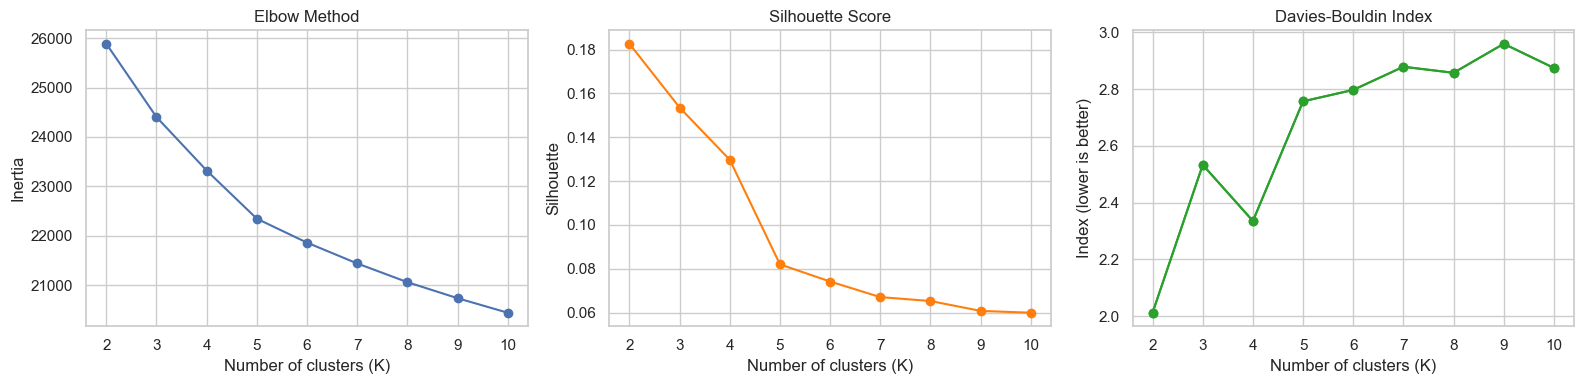

Selected K (highest silhouette): 2
k                        2.000000
inertia              25887.284897
silhouette               0.182672
davies_bouldin           2.011865
calinski_harabasz      477.599182


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(metrics["k"], metrics["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(metrics["k"], metrics["silhouette"], marker="o", color="tab:orange")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette")

axes[2].plot(metrics["k"], metrics["davies_bouldin"], marker="o", color="tab:green")
axes[2].plot(metrics["k"], metrics["davies_bouldin"], marker="o", color="tab:green")
axes[2].set_title("Davies-Bouldin Index")
axes[2].set_xlabel("Number of clusters (K)")
axes[2].set_ylabel("Index (lower is better)")
plt.tight_layout()
plt.show()

selected_k = choose_k(metrics)
print("Selected K (highest silhouette):", selected_k)
print(metrics.loc[metrics["silhouette"].idxmax()].to_string())

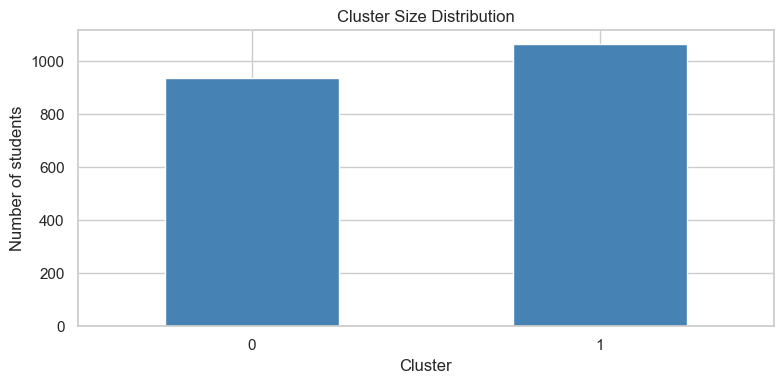

,student_count
cluster,
0,936
1,1064


In [5]:
selected_model = models[selected_k]
labels = selected_model.predict(X_scaled.to_numpy())
assignments = pd.DataFrame({"student_id": cleaned["student_id"].to_numpy(), "cluster": labels})
cluster_counts = assignments["cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
cluster_counts.plot(kind="bar", color="steelblue")
plt.title("Cluster Size Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
cluster_counts.to_frame("student_count")

## 4. PCA visualization

PCA projects the high-dimensional matrix onto two directions retaining maximum variance. The scatter is useful for exploration only: PCA can hide or distort cluster boundaries, and explained variance indicates how much of the original variation this 2D view retains.

Explained variance ratio: [0.22921841 0.09466776]
Total 2D explained variance: 0.3238861624642277


/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_t

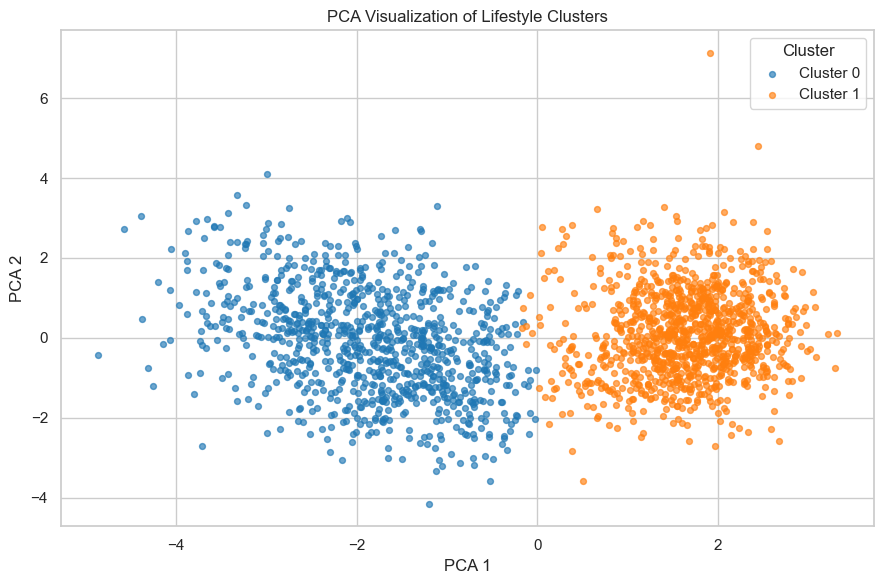

In [6]:
pca, coordinates = fit_pca(X_scaled)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total 2D explained variance:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(9, 6))
palette = sns.color_palette("tab10", n_colors=selected_k)
for cluster in range(selected_k):
    mask = labels == cluster
    plt.scatter(coordinates[mask, 0], coordinates[mask, 1], s=18, alpha=0.65,
                color=palette[cluster], label=f"Cluster {cluster}")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("PCA Visualization of Lifestyle Clusters")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 5. Cluster interpretation

Profiles use actual cleaned student averages. Guest frequency and music frequency are joined from raw data by student ID; CGPA, branch, gender, and age are excluded from the clustering model and labels.

In [7]:
profiles = build_cluster_profiles(cleaned, assignments, raw_df=raw)
profiles

,cluster,sleep_time,wake_time,sleep_duration,study_hours,cleanliness_level,noise_tolerance,social_activity,introvert_extrovert,guest_frequency,music_frequency,cluster_size
0,0,6.225363,8.781645,7.915598,3.272361,3.297009,3.935897,3.929487,3.973291,1.856838,1.806818,936
1,1,21.854718,6.937472,8.004483,4.067726,4.219925,1.894737,2.688910,2.148496,1.812030,1.820912,1064


### Evidence-based interpretation

The two-cluster solution separates the data by more than just sleep timing:

- **Cluster 0** has an average sleep time around 06:14, a wake time around 08:47, and comparatively high noise tolerance and social activity. It can be described as an **early-sleeping, socially active and noise-tolerant** group.
- **Cluster 1** has an average sleep time around 21:51, a wake time around 06:56, higher cleanliness and study hours, and lower noise/social values. It can be described as a **late-evening, quiet, cleanliness-conscious and study-focused** group.

Guest and music averages are ordinal estimates mapped as Rarely=1, Sometimes=2, Often=3, Very Often=4. These labels are interpretations, not new model features.

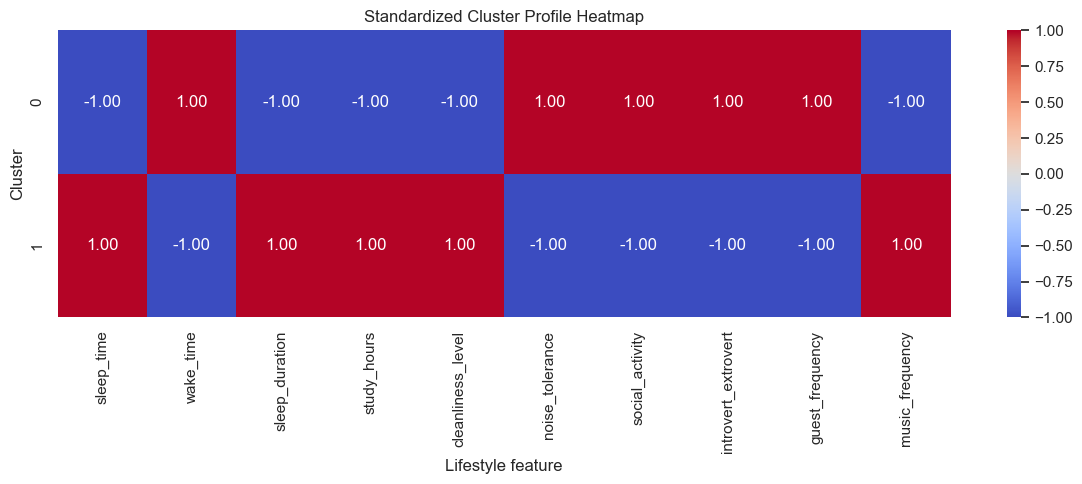

In [8]:
profile_columns = [c for c in ["sleep_time", "wake_time", "sleep_duration", "study_hours", "cleanliness_level", "noise_tolerance", "social_activity", "introvert_extrovert", "guest_frequency", "music_frequency"] if c in profiles.columns]
heatmap_data = profiles.set_index("cluster")[profile_columns]
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std(ddof=0)
plt.figure(figsize=(12, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Standardized Cluster Profile Heatmap")
plt.xlabel("Lifestyle feature")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

## 6. Save outputs

Write assignments, measured profiles, metric comparisons, the selected K-Means model, PCA model, and feature-column order under `models/`.

In [9]:
models_dir = PROJECT_DIR / "models"
save_clustering_artifacts(str(models_dir), assignments, profiles, metrics, selected_model, pca, X_scaled.columns.tolist())
print("Saved clustering artifacts to:", models_dir)
print(cluster_counts.to_string())

Saved clustering artifacts to: /Users/ananyaa/Desktop/DormMatch/models
cluster
0     936
1    1064
